# 🚀 Модуль 13. Урок 1. Бизнес-метрики и Unit-экономика: CAC, LTV, Retention и маржинальность

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_13_soft_skills_storytelling/lesson_01_business_metrics_unit_economics.ipynb)

## 📌 Бизнес-контекст и методология
Аналитик, считающий только среднее и p-value, бесполезен бизнесу. 
Главный язык общения с топ-менеджментом и инвесторами — **Unit-экономика**. 
Она отвечает на вопрос: «Зарабатывает ли компания на одном конкретном клиенте (юните), или каждый новый пользователь увеличивает чистый убыток?». 
Золотое правило масштабирования стартапа: $LTV / CAC \ge 3.0$ при сроке окупаемости (Payback Period) $< 12$ месяцев.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Рассчитаем Unit-экономику когорты: стоимость привлечения (CAC), валовую маржу, средний чек и итоговый LTV.

In [2]:
# Параметры Unit-экономики B2B SaaS продукта
cac = 450.0            # Стоимость привлечения клиента ($)
arpu_month = 95.0      # Выручка в месяц ($)
gross_margin = 0.82    # Валовая маржинальность (82%)
churn_rate_month = 0.04 # Месячный отток (4%)

lifetime_months = 1 / churn_rate_month  # 25 месяцев
ltv = arpu_month * gross_margin * lifetime_months  # $1,947.50
ltv_cac_ratio = ltv / cac
payback_months = cac / (arpu_month * gross_margin)

print(f"LTV (Lifetime Value):   ${ltv:,.2f}")
print(f"CAC (Acquisition Cost): ${cac:,.2f}")
print(f"LTV / CAC отношение:    {ltv_cac_ratio:.2f}x (Здоровый бизнес > 3.0x)")
print(f"Срок окупаемости (Payback): {payback_months:.1f} мес.")

LTV (Lifetime Value):   $1,947.50
CAC (Acquisition Cost): $450.00
LTV / CAC отношение:    4.33x (Здоровый бизнес > 3.0x)
Срок окупаемости (Payback): 5.8 мес.


### 📊 Визуализация: Водопад Unit-экономики (Waterfall Chart)
Водопадная диаграмма ниже раскладывает валовую выручку на составляющие: от CAC и себестоимости серверов до чистой прибыли на клиента.

C:\Users\serge\AppData\Local\Temp\ipykernel_26924\2472608043.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(stages, rotation=25, ha='right', fontsize=9)


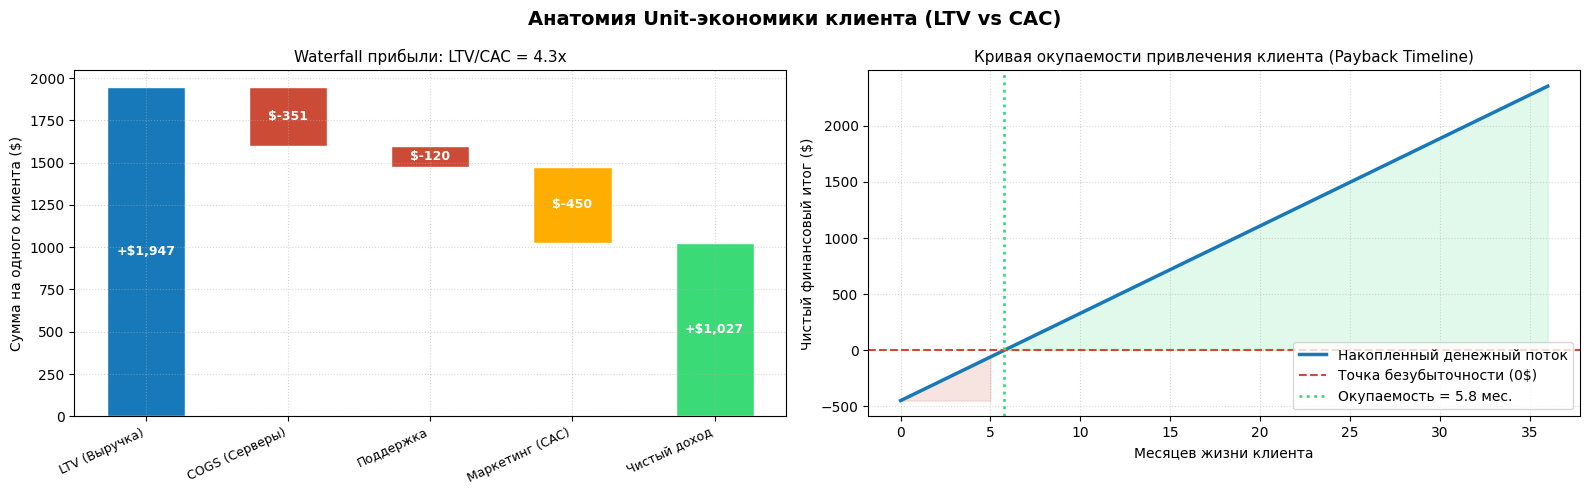

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Анатомия Unit-экономики клиента (LTV vs CAC)', fontsize=14, fontweight='bold')

# 1. Водопад формирования чистой прибыли на юнит
ax1 = axes[0]
stages = ['LTV (Выручка)', 'COGS (Серверы)', 'Поддержка', 'Маркетинг (CAC)', 'Чистый доход']
values = [ltv, -ltv*(1-gross_margin), -120, -cac, 0]
values[-1] = sum(values[:-1])

bottoms = [0, ltv - ltv*(1-gross_margin), ltv - ltv*(1-gross_margin) - 120, ltv - ltv*(1-gross_margin) - 120 - cac, 0]
colors = ['#1779ba', '#cc4b37', '#cc4b37', '#ffae00', '#3adb76']

bars = ax1.bar(stages, [abs(v) for v in values], bottom=bottoms, color=colors, edgecolor='white', width=0.55)
ax1.set_title(f'Waterfall прибыли: LTV/CAC = {ltv_cac_ratio:.1f}x', fontsize=11)
ax1.set_ylabel('Сумма на одного клиента ($)')
ax1.set_xticklabels(stages, rotation=25, ha='right', fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.5)

for i, b in enumerate(bars):
    val = values[i]
    y_pos = bottoms[i] + b.get_height() / 2
    sign = '+' if val > 0 else ''
    ax1.text(b.get_x() + b.get_width()/2, y_pos, f'{sign}${val:,.0f}', ha='center', va='center',
             color='white', fontweight='bold', fontsize=9)

# 2. График окупаемости CAC во времени (Payback Curve)
ax2 = axes[1]
months_timeline = np.arange(0, 37)
cumulative_contribution = -cac + (arpu_month * gross_margin) * months_timeline

ax2.plot(months_timeline, cumulative_contribution, color='#1779ba', linewidth=2.5, label='Накопленный денежный поток')
ax2.axhline(0, color='#cc4b37', linestyle='--', linewidth=1.5, label='Точка безубыточности (0$)')
ax2.axvline(payback_months, color='#3adb76', linestyle=':', linewidth=2, label=f'Окупаемость = {payback_months:.1f} мес.')
ax2.fill_between(months_timeline, -cac, cumulative_contribution, where=(cumulative_contribution < 0), color='#cc4b37', alpha=0.15)
ax2.fill_between(months_timeline, 0, cumulative_contribution, where=(cumulative_contribution >= 0), color='#3adb76', alpha=0.15)

ax2.set_title('Кривая окупаемости привлечения клиента (Payback Timeline)', fontsize=11)
ax2.set_xlabel('Месяцев жизни клиента')
ax2.set_ylabel('Чистый финансовый итог ($)')
ax2.legend(loc='lower right')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Влияние оттока на отношение LTV/CAC
Если месячный отток вырастет с 4% до 7%, рассчитайте новое отношение LTV / CAC и определите, останется ли юнит-экономика здоровой (> 3.0x).

In [4]:
### ВАШ КОД ЗДЕСЬ
new_churn = 0.07
new_ltv = arpu_month * gross_margin * (1 / new_churn)
new_ratio = new_ltv / cac

print(f"Новый LTV при оттоке 7%: ${new_ltv:,.2f}")
print(f"Новое отношение LTV/CAC:  {new_ratio:.2f}x")

assert new_ratio < ltv_cac_ratio, "Рост оттока обязан снижать LTV/CAC"
print("✅ Тест успешно пройден!")

Новый LTV при оттоке 7%: $1,112.86
Новое отношение LTV/CAC:  2.47x
✅ Тест успешно пройден!


### 💼 Главный урок Unit-экономики:
Снижение оттока (Retention) влияет на LTV в разы сильнее, чем снижение стоимости привлечения (CAC). Удерживать старых клиентов всегда выгоднее, чем заливать дырявую воронку новым платным трафиком.